In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import torch

import hornbill
from hornbill import GridPosterior, choose_setting, operators, sample_outcomes

## Bayesian estimation of $\gamma$ from Ramsey shots

The qubit starts in $|0\rangle$, is put in superposition with $H$, evolves under $\mathcal H = -\tfrac{\gamma}{2} Z$ for time $t$ (i.e. $R_z(2\gamma t)$), and is rotated back with $H$. Measuring gives

$$P(0 \mid \gamma, t) = \cos^2(\gamma t), \qquad P(1 \mid \gamma, t) = \sin^2(\gamma t).$$

`idea.ipynb` inverted the exact probability with `arccos`, but in an experiment we only see a finite number of 0/1 shots. Here we keep a posterior $p(\gamma \mid \text{shots})$ on a grid and update it with Bayes' rule after each shot.

The likelihood is periodic in $\gamma$ with period $\pi/t$ and symmetric under $\gamma \to -\gamma$, so we restrict the prior to $\gamma \in [0, \pi/2]$, where $t = 1$ is unambiguous.

In [2]:
def model(gamma, t):
    """Likelihood matrix P(k | gamma, t), shape (*gamma.shape, 2), built from the circuit.

    The gates are batched over gamma, so one call evaluates the whole grid.
    """
    gamma = torch.as_tensor(gamma, dtype=torch.float64)
    u = operators.H @ operators.rz(2 * gamma * t) @ operators.H
    amplitudes = u[..., :, 0]  # U|0>
    return amplitudes.real**2 + amplitudes.imag**2

grid = torch.linspace(0, math.pi / 2, 4001, dtype=torch.float64)
gamma_true = torch.tensor(0.9, dtype=torch.float64)

# sanity check against the closed form and the StateVector circuit
sv = hornbill.StateVector(1).apply(operators.H, [0]).apply(operators.rz(2 * gamma_true), [0]).apply(operators.H, [0])
print(model(gamma_true, 1.0), sv.probabilities(), torch.cos(gamma_true) ** 2)

tensor([0.3864, 0.6136], dtype=torch.float64) tensor([0.3864, 0.6136], dtype=torch.float64) tensor(0.3864, dtype=torch.float64)


### Fixed evolution time

Use $t = 1$ for every shot. The posterior narrows like $1/\sqrt N$.

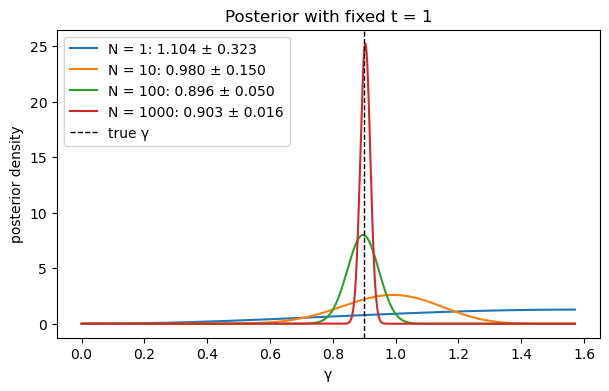

In [3]:
gen = torch.Generator().manual_seed(0)
posterior = GridPosterior(grid)

fig, ax = plt.subplots(figsize=(7, 4))
shots_so_far = 0
for n_total in [1, 10, 100, 1000]:
    shots = sample_outcomes(model(gamma_true, 1.0), n_total - shots_so_far, generator=gen)
    posterior.update(model(grid, 1.0), shots)
    shots_so_far = n_total
    density = posterior.weights / (grid[1] - grid[0])
    ax.plot(grid, density, label=f"N = {n_total}: {posterior.mean():.3f} ± {posterior.std():.3f}")
ax.axvline(gamma_true, color="k", ls="--", lw=1, label="true γ")
ax.set_xlabel("γ")
ax.set_ylabel("posterior density")
ax.set_title("Posterior with fixed t = 1")
ax.legend()
plt.show()

### Adaptive evolution time

Longer $t$ makes $P(0)$ vary faster with $\gamma$ (the Fisher information per shot is $4t^2$), but a single long-$t$ measurement can't tell apart values of $\gamma$ that differ by $\pi/t$. The adaptive strategy resolves this: before each shot, `choose_setting` picks the $t$ from a candidate set that minimises the *expected* posterior variance after the shot. Early on, when the posterior is broad, short times are best. As it narrows, longer times become safe.

Candidate times are $t \in \{0.5, 1, 2, \dots, 64\}$.

In [4]:
times = [0.5 * 2**j for j in range(8)]

def run(adaptive, n_shots, seed):
    gen = torch.Generator().manual_seed(seed)
    posterior = GridPosterior(grid)
    stds, errors, total_time, chosen = [], [], [], []
    elapsed = 0.0
    for _ in range(n_shots):
        t = choose_setting(posterior, model, times)[0] if adaptive else 1.0
        posterior.update(model(grid, t), sample_outcomes(model(gamma_true, t), 1, generator=gen))
        elapsed += t
        stds.append(posterior.std().item())
        errors.append((posterior.mean() - gamma_true).item())
        total_time.append(elapsed)
        chosen.append(t)
    return np.array(stds), np.array(errors), np.array(total_time), chosen, posterior

n_shots, seeds = 300, range(10)
fixed = [run(False, n_shots, s) for s in seeds]
adapt = [run(True, n_shots, s) for s in seeds]

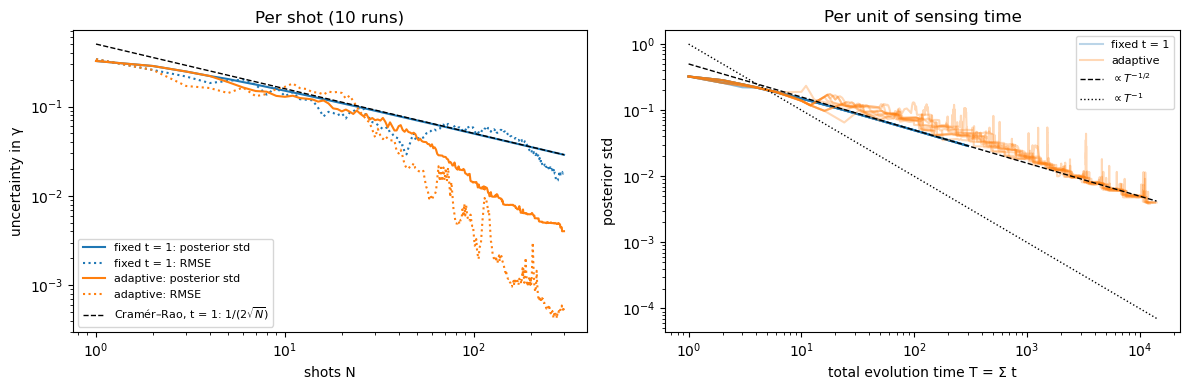

after 300 shots: fixed std 2.88e-02, adaptive std 4.02e-03


In [5]:
n = np.arange(1, n_shots + 1)
rmse = lambda runs: np.sqrt(np.mean([r[1] ** 2 for r in runs], axis=0))
median_std = lambda runs: np.median([r[0] for r in runs], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.loglog(n, median_std(fixed), label="fixed t = 1: posterior std")
ax.loglog(n, rmse(fixed), ":", color="C0", label="fixed t = 1: RMSE")
ax.loglog(n, median_std(adapt), label="adaptive: posterior std")
ax.loglog(n, rmse(adapt), ":", color="C1", label="adaptive: RMSE")
ax.loglog(n, 1 / (2 * np.sqrt(n)), "k--", lw=1, label=r"Cramér–Rao, t = 1: $1/(2\sqrt{N})$")
ax.set_xlabel("shots N")
ax.set_ylabel("uncertainty in γ")
ax.set_title(f"Per shot ({len(seeds)} runs)")
ax.legend(fontsize=8)

ax = axes[1]
for runs, label, c in [(fixed, "fixed t = 1", "C0"), (adapt, "adaptive", "C1")]:
    for i, r in enumerate(runs):
        ax.loglog(r[2], r[0], color=c, alpha=0.3, label=label if i == 0 else None)
T = np.logspace(0, np.log10(max(r[2][-1] for r in adapt)), 50)
ax.loglog(T, 1 / (2 * np.sqrt(T)), "k--", lw=1, label=r"$\propto T^{-1/2}$")
ax.loglog(T, 1 / T, "k:", lw=1, label=r"$\propto T^{-1}$")
ax.set_xlabel("total evolution time T = Σ t")
ax.set_ylabel("posterior std")
ax.set_title("Per unit of sensing time")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"after {n_shots} shots: fixed std {median_std(fixed)[-1]:.2e}, adaptive std {median_std(adapt)[-1]:.2e}")

Per shot, the adaptive strategy wins by a large factor because it uses long evolution times. The fairer comparison counts total evolution time $T = \sum t$ (right), and there it does **no better** than fixed $t = 1$: the posterior std ends up near the $T^{-1/2}$ line.

The main peak isn't the problem. Below is the final posterior of one adaptive run on a log scale. The peak at the true $\gamma$ is as narrow as $t = 64$ allows. But a fraction of a percent of the weight remains on **aliased peaks**: values $\gamma'$ with $\gamma' t \equiv \pm\gamma t \pmod \pi$, for which $\cos^2(\gamma' t) = \cos^2(\gamma t)$, so the $t = 64$ shots can't tell them apart. The largest are the reflections $\gamma' = k\pi/64 - \gamma$ about $0.016$ either side, which shorter-$t$ shots have only partly suppressed. They are many peak-widths away, so weights of $\sim 10^{-3}$ still dominate the variance. This is also why the RMSE (dotted, left) is far below the posterior std: in these 10 runs no estimate landed on an alias, and the std is the posterior honestly reporting that one could have.

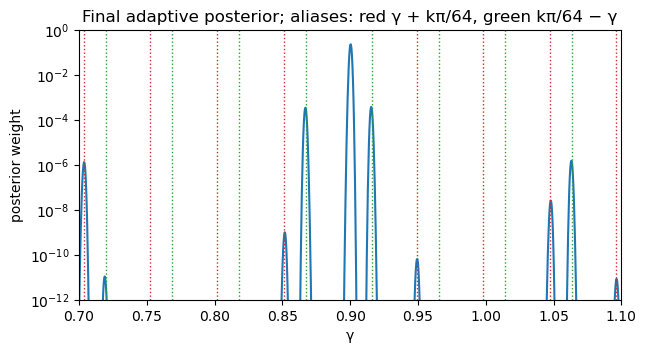

weight within 0.01 of the true value: 0.9965
posterior std: 4.8e-03, std of the main peak alone: 7.2e-04
ideal for 135 shots at t = 64, 1/(2 t sqrt(N)): 6.7e-04


In [6]:
final = adapt[0][4]
w = final.weights.numpy()
g = grid.numpy()
near = np.abs(g - gamma_true.item()) < 0.01

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(g, np.maximum(w, 1e-20))
gt = gamma_true.item()
for k in range(-4, 5):
    if k:
        ax.axvline(gt + k * math.pi / 64, color="C3", ls=":", lw=1)
for k in range(30, 44):
    ax.axvline(k * math.pi / 64 - gt, color="C2", ls=":", lw=1)
ax.set_ylim(1e-12, 1)
ax.set_xlim(0.7, 1.1)
ax.set_xlabel("γ")
ax.set_ylabel("posterior weight")
ax.set_title("Final adaptive posterior; aliases: red γ + kπ/64, green kπ/64 − γ")
plt.show()

local_std = np.sqrt(np.sum(w[near] * (g[near] - gamma_true.item()) ** 2) / w[near].sum())
n64 = sum(t == 64 for t in adapt[0][3])
print(f"weight within 0.01 of the true value: {w[near].sum():.4f}")
print(f"posterior std: {final.std():.1e}, std of the main peak alone: {local_std:.1e}")
print(f"ideal for {n64} shots at t = 64, 1/(2 t sqrt(N)): {1 / (2 * 64 * math.sqrt(n64)):.1e}")

Greedy one-step lookahead doesn't fully clear the ambiguity before moving to a longer $t$. Getting true $T^{-1}$ (Heisenberg-like) scaling from a single qubit needs a schedule that spends enough shots at each time to rule out the aliases before doubling it, as in Kitaev-style / robust phase estimation (e.g. Higgins et al., *Nature* 450, 393 (2007)). Beating $T^{-1/2}$ at *fixed* $t$ needs entangled probes such as GHZ states, which is the comparison to make next.

The chosen times for one run:

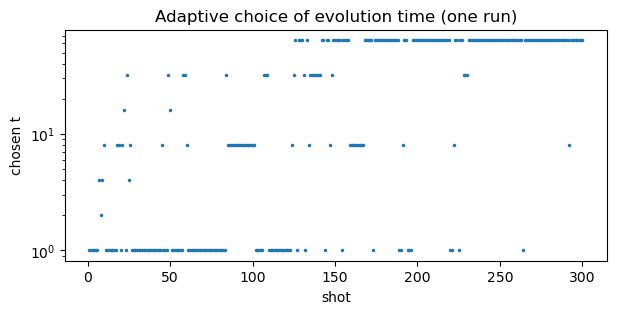

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.semilogy(n, adapt[0][3], ".", ms=3)
ax.set_xlabel("shot")
ax.set_ylabel("chosen t")
ax.set_title("Adaptive choice of evolution time (one run)")
plt.show()